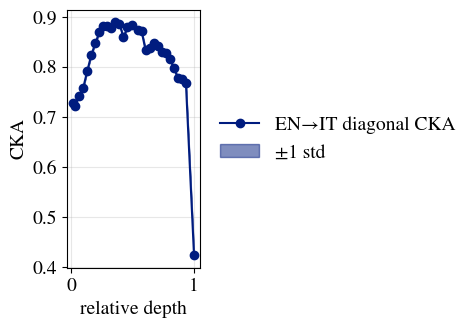

In [8]:
import glob
import re
import sys
import numpy as np
import matplotlib.pyplot as plt

sys.path.append('../../')
from utils import depths
from utils_plots import apply_plot_style, get_layers

colors, markers, _linestyles = apply_plot_style()

# --- Target configuration ---
base = '../results/CKA'
modelA = 'deepseek'
modelB = 'deepseek'
model_for_depth = 'deepseek'
aux_A = 'source'
aux_B = 'target'
languageA = 'english'
languageB = 'italian'
batch_shuffle = 0
n_files = 100
min_token_length = 35
mask = 2
Nbits = 0
n_tokens = 20
avg_tokens = 0

pattern = (
    f'{base}/batch_shuffle_{batch_shuffle}/'
    f'modelA_{modelA}/modelB_{modelB}/'
    f'aux_A_{aux_A}/aux_B_{aux_B}/'
    f'n_files_{n_files}/min_token_length_{min_token_length}/'
    f'languageA_{languageA}/languageB_{languageB}/'
    f'mask_{mask}/Nbits_{Nbits}/seed_*/'
    f'n_tokens_{n_tokens}_avg_{avg_tokens}_cka.npy'
)
paths = sorted(glob.glob(pattern))
assert len(paths) > 0, f'No files found for pattern:\n{pattern}'

def extract_seed(path):
    m = re.search(r'/seed_(\d+)/', path)
    return int(m.group(1)) if m else -1

diags = []
used_seeds = []
for p in paths:
    mat = np.load(p)
    diags.append(mat.diagonal())
    used_seeds.append(extract_seed(p))

diags = np.stack(diags, axis=0)
mean_diag = diags.mean(axis=0)
std_diag = diags.std(axis=0)

layers = get_layers(model_for_depth, depths)
x = layers / depths[model_for_depth]

fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))
label = 'EN→IT diagonal CKA'
ax.plot(x, mean_diag, label=label, color=colors[0], marker='o')
ax.fill_between(x, mean_diag - std_diag, mean_diag + std_diag, color=colors[0], alpha=0.5, label='±1 std')
ax.errorbar(x, mean_diag, yerr=std_diag, fmt='none', ecolor=colors[0], elinewidth=1.0, capsize=2, alpha=0.9)

ax.set_xlabel('relative depth')
ax.set_ylabel('CKA')
ax.grid(True, alpha=0.3)
ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=False)

plt.show()

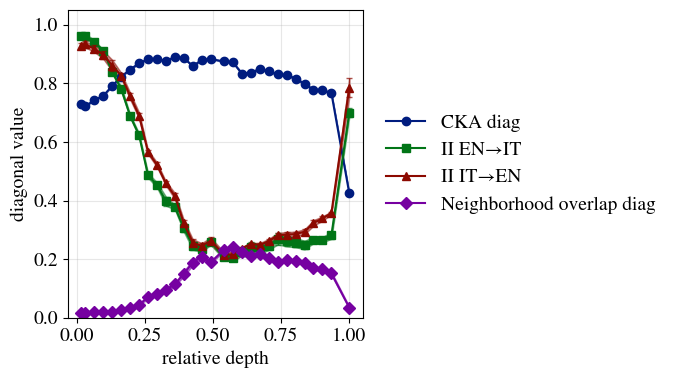

In [9]:
import glob
import re
import sys
import numpy as np
import matplotlib.pyplot as plt

sys.path.append('../../')
from utils import depths
from utils_plots import apply_plot_style, get_layers

colors, markers, _linestyles = apply_plot_style()

cfg = {
    'modelA': 'deepseek',
    'modelB': 'deepseek',
    'model_for_depth': 'deepseek',
    'aux_A': 'source',
    'aux_B': 'target',
    'languageA': 'english',
    'languageB': 'italian',
    'batch_shuffle': 0,
    'min_token_length': 35,
    'mask': 2,
    'Nbits': 0,
    'n_tokens': 20,
    'avg_tokens': 0,
}

base_cka = '../results/CKA'
base_ii = '../results/santiago'
n_files_cka = 100
n_files_ii = 500
k_ii = 10


def extract_seed(path):
    m = re.search(r'/seed_(\d+)/', path)
    return int(m.group(1)) if m else -1


def load_diag_series(pattern):
    paths = sorted(glob.glob(pattern))
    assert len(paths) > 0, f'No files found for pattern:\n{pattern}'
    mats = [np.load(p) for p in paths]
    diags = np.stack([m.diagonal() for m in mats], axis=0)
    seeds = [extract_seed(p) for p in paths]
    return {
        'paths': paths,
        'seeds': seeds,
        'mean': diags.mean(axis=0),
        'std': diags.std(axis=0),
    }


def build_prefix(base, n_files, include_k=False):
    prefix = (
        f"{base}/batch_shuffle_{cfg['batch_shuffle']}/"
        f"modelA_{cfg['modelA']}/modelB_{cfg['modelB']}/"
        f"aux_A_{cfg['aux_A']}/aux_B_{cfg['aux_B']}/"
        f"n_files_{n_files}/min_token_length_{cfg['min_token_length']}/"
        f"languageA_{cfg['languageA']}/languageB_{cfg['languageB']}/"
        f"mask_{cfg['mask']}/"
    )
    if include_k:
        prefix += f'k_{k_ii}/'
    prefix += f"Nbits_{cfg['Nbits']}/seed_*/"
    return prefix


pattern_cka = (
    build_prefix(base_cka, n_files_cka)
    + f"n_tokens_{cfg['n_tokens']}_avg_{cfg['avg_tokens']}_cka.npy"
)
pattern_ii_ab = (
    build_prefix(base_ii, n_files_ii, include_k=True)
    + f"n_tokens_{cfg['n_tokens']}_avg_{cfg['avg_tokens']}_AB.npy"
)
pattern_ii_ba = (
    build_prefix(base_ii, n_files_ii, include_k=True)
    + f"n_tokens_{cfg['n_tokens']}_avg_{cfg['avg_tokens']}_BA.npy"
)
pattern_overlap = (
    build_prefix(base_ii, n_files_ii, include_k=True)
    + f"n_tokens_{cfg['n_tokens']}_avg_{cfg['avg_tokens']}_alignment.npy"
)

cka = load_diag_series(pattern_cka)
ii_ab = load_diag_series(pattern_ii_ab)
ii_ba = load_diag_series(pattern_ii_ba)
overlap = load_diag_series(pattern_overlap)

layers = get_layers(cfg['model_for_depth'], depths)
x = layers / depths[cfg['model_for_depth']]

fig, ax = plt.subplots(1, 1, figsize=(7.0, 4.))


def plot_with_band(xvals, stat, color, marker, label):
    ax.plot(xvals, stat['mean'], color=color, marker=marker, label=label)
    ax.fill_between(
        xvals,
        stat['mean'] - stat['std'],
        stat['mean'] + stat['std'],
        color=color,
        alpha=0.5,
    )
    ax.errorbar(
        xvals,
        stat['mean'],
        yerr=stat['std'],
        fmt='none',
        ecolor=color,
        elinewidth=1.0,
        capsize=2,
        alpha=0.7,
    )


plot_with_band(x, cka, colors[0], 'o', 'CKA diag')
plot_with_band(x, ii_ab, colors[1], 's', f"II {cfg['languageA'][:2].upper()}→{cfg['languageB'][:2].upper()}")
plot_with_band(x, ii_ba, colors[2], '^', f"II {cfg['languageB'][:2].upper()}→{cfg['languageA'][:2].upper()}")
plot_with_band(x, overlap, colors[3], 'D', 'Neighborhood overlap diag')

ax.set_xlabel('relative depth')
ax.set_ylabel('diagonal value')
ax.set_ylim(0, 1.05)
ax.grid(True, alpha=0.3)
ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=False)

plt.show()
